# QPDK filled qubit test chip — the qubit test chip with QPDK's vortex-trap fill (Quantcore PDK rebuild)

**What the chip is.** gdsfactory **quantum-rf-pdk** (QPDK) `qpdk/samples/filled_test_chip.py`
(`filled_qubit_test_chip`), <https://github.com/gdsfactory/quantum-rf-pdk> — **MIT licence** (gdsfactory 2024;
depth-1 clone read 2026-11-03, never executed). Spec: `docs/designs/qpdk/filled_qubit_test_chip.md`. QPDK says
the sample "roughly corresponds" to Tuokkola et al., Nat. Commun. 2025 (near-millisecond transmons). QPDK loads
the [qubit test chip](qubit_test_chip.ipynb) YAML **unchanged**, fills the ground plane with vortex-trapping
holes — `fill_magnetic_vortices(rectangle_size=(15, 15), gap=70, stagger=2)`, which fills the chip's bounding box
with 15 × 15 µm etched squares on an 85 µm pitch, each row staggered by 2 µm, keeping 80 µm from every etched,
drawn or waveguide shape (`_EXCLUDE_LAYERS_DEFAULT_M1` in `qpdk/utils.py`) — adds a 100 µm etched `chip_edge`
around the layout and converts the result to a negative mask.

This notebook **rebuilds** it on the Quantcore PDK (not a replica); we distribute the rebuild under GPL-3.0.

| topic | QPDK source | this rebuild (Quantcore PDK) |
|---|---|---|
| layout | the qubit test chip, unchanged | `qubit_test_chip.json` loaded unchanged: the 7.5 mm die, pads 100 µm (`frame.pad_edge`) from the edge, the whole layout centred (pads included), trilayer SQUIDs (see that notebook) |
| chip edge | 100 µm etched `chip_edge` around the layout | the Quantcore die frame (dicing L's, alignment grids, boundary 100/0), device ID "QPDK-FQTC" |
| cheese | **QPDK's vortex fill**: 15 µm squares, 85 µm pitch, 80 µm clear of every shape | **the original wins:** the same fill as the chip's `cheese` rule (`QP.vortex_fill(d)` → a rule dict): the build draws it instead of the PDK band, and `export_fab` / `qcc mask` keep it |
| substrate, junctions | Al on Si, evaporated Al SQUIDs | sapphire 650 µm, εr 10.25; Quantcore trilayer SQUIDs |

**The fill, as the PDK can express it:** a `CheeseRule` of 15 µm squares with 70 µm gaps over the whole design
area, at least 70 µm from the 3/0 keep-outs (= 80 µm from every route's CPW gap, since 3/0 already adds 10 µm
round each CPW; around components 3/0 adds 24 µm, so the holes there stay ≥ 94 µm from the etch bbox). Not
reproduced: the 2 µm row stagger (a `CheeseRule` is a square grid), and QPDK fills only the layout's bounding box
while the rebuild fills the whole die inside the frame. Simulation exports never get cheese, so the FEM jobs equal the unfilled chip's. The fill is the chip's `cheese`
rule (a dict of `CheeseRule` fields, chip parameters since 2026-11-04): the build draws it into the ground-grid
layer, so the layout, the snapshots and KLive show it, and `export_fab` / `qcc mask` keep it (cheese source
`build`).

## 1 · Setup

`LIVE` follows `QCC_LIVE` (default on: KLayout opens and redraws after every change; `QCC_LIVE=0` for batch
runs). `RUN_FEM = False` keeps the FEM step at "export only"; `True` solves the jobs in a new batch AEDT
2024 R1 (if installed). `FULL_FAB = False` skips the fab-only corner rounding in step 13 (`qcc mask` does the
full file). `_qpdk` holds the QPDK cell defaults shared by the QPDK notebooks (launcher, double-pad transmon,
IDC, the trilayer SQUID, the die box and the centring check).

In [1]:
%config InlineBackend.figure_formats = ["png"]
import os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
sys.path.insert(0, str(ROOT / "examples" / "designs" / "qpdk"))
from _common import *                            # tables, snapshots, PDK and FEM step helpers
import _qpdk as QP                               # QPDK cell defaults, trilayer SQUID, die box, centring
from quantcore_circuits.designer import Designer
LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
RUN_FEM = False                                  # True: solve the exported jobs in a new batch AEDT 2024 R1
FULL_FAB = False                                 # True: also round the corners in the fab export
OUT = Path("examples/designs/qpdk")              # design JSON + final snapshots
STEPS = Path("build/snapshots/filled_qubit_test_chip")           # step-by-step snapshots (build/ is not kept in the repo)

## 2 · The PDK this chip uses

Every rule below comes from the PDK object (`get_pdk()`), not from this notebook: the stack feeds the LOM
estimates and the FEM exports, the frame and pad rule shape the die, the junction rule sizes the junctions,
and the cheese, 3/0 keep-out and corner-rounding rules apply when the mask is written.

In [2]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

## 3 · The die, pads, components and routes — loaded from the qubit test chip

QPDK builds this chip from the qubit test chip's YAML, so the rebuild loads `qubit_test_chip.json` read-only
(`d.path = None`: building here never rewrites that file) and changes only the name, the device ID and the
cheese mode. Everything in steps 3–6 of the [qubit test chip](qubit_test_chip.ipynb) (die, the PDK pad rule,
trilayer SQUIDs, routes, centring) comes with it. Re-run that notebook first when it changes.

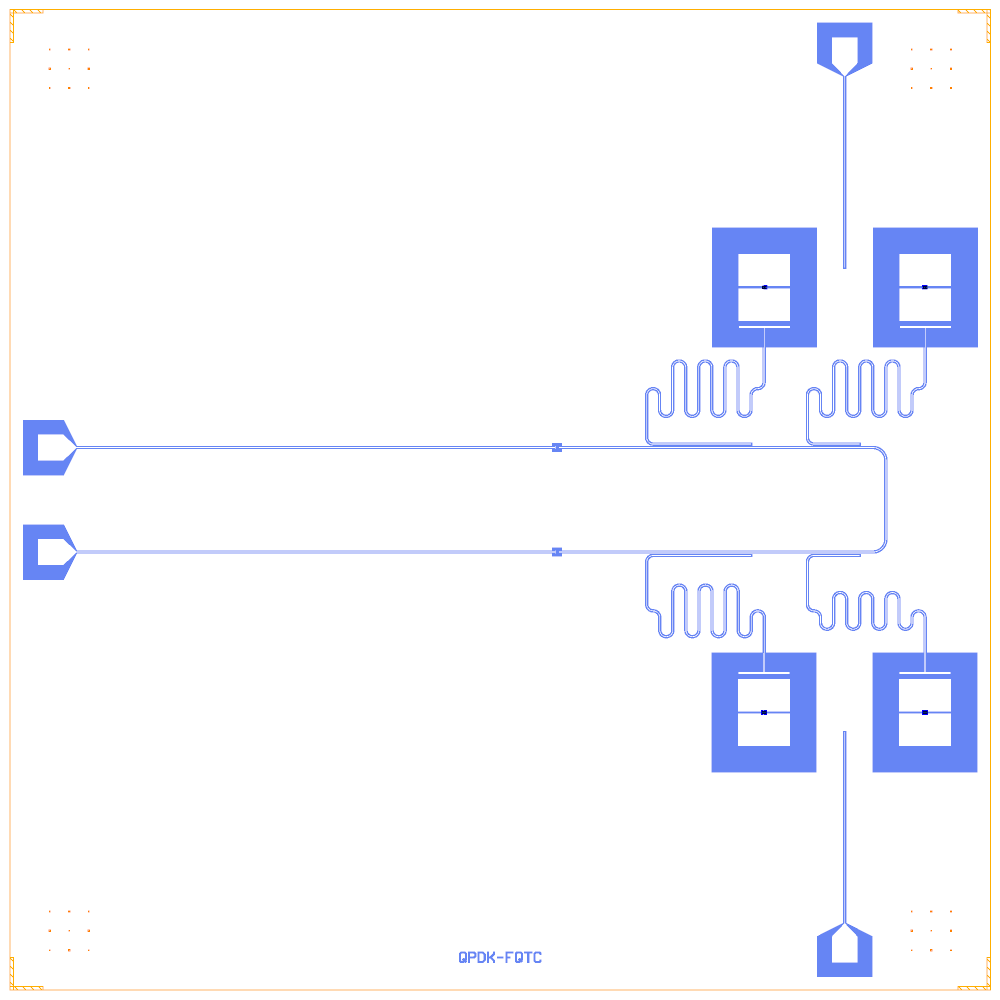

junctions: {'Q1': 'Quantcore Squid', 'Q2': 'Quantcore Squid', 'Q3': 'Quantcore Squid', 'Q4': 'Quantcore Squid'}


In [3]:
d = Designer.load(OUT / "qubit_test_chip.json", out=Path("build/filled_qubit_test_chip.oas"), live=False)
d.path = None                                    # do not write back to qubit_test_chip.json
d.live = LIVE
d.data["name"] = "filled_qubit_test_chip"
d.data["chip"]["params"].update(
    name_chip="QPDK-FQTC",                       # device ID on the Quantcore die frame
    cheese="original",                           # no PDK band; the original's fill is set in step 6
)
snap(d, STEPS / "1_die.png", size=(1000, 1000), width=400)
print("junctions:", {n: s["params"].get("junction_type") for n, s in d.data["instances"].items() if n.startswith("Q")})

**Pads:** the four launchers of the qubit test chip, placed with `edge="auto"` there, so their outer etch is
100 µm (`frame.pad_edge`) from the die edge. **Components and routes:** the same 10 instances and 9 routes.

In [4]:
display(Markdown(pads_md(d)))
print({k: round(v, 1) for k, v in d.result.route_lengths().items()})

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| PAD_IN | `BondPad` | w | 100.0 | ✓ |
| PAD_OUT | `BondPad` | w | 100.0 | ✓ |
| PAD_FT | `BondPad` | n | 100.0 | ✓ |
| PAD_FB | `BondPad` | s | 100.0 | ✓ |

{'FL_IN': 3638.5, 'FL': 5671.2, 'FL_OUT': 3638.5, 'R1': 5000.0, 'R2': 4600.0, 'R3': 3600.0, 'R4': 4800.0, 'FLUX_T': 1465.0, 'FLUX_B': 1465.0}


## 6 · The fill rule, sim groups and save

`QP.vortex_fill(d)` is QPDK's `fill_magnetic_vortices(rectangle_size=(15, 15), gap=70, stagger=2)` as a PDK
`CheeseRule` (built with `original_cheese(15, 85, clearance=70, d)`: 80 µm minus the PDK route margin, 10 µm).
Its fields go on the chip as the `cheese` rule dict, with `rows` 1000 so that it fills all the free ground, and the
chip is rebuilt: the fill is now part of the build. The sim groups come with the loaded design (one per qubit
with its readout and the probeline). Then the design is saved.

In [5]:
FILL = QP.vortex_fill(d)                         # QPDK's vortex fill as a PDK CheeseRule
d.data["chip"]["params"]["cheese"] = {"size": FILL.size, "gap": FILL.gap, "rows": 1000, "clearance": FILL.clearance}
print(FILL)
d.show()                                         # rebuild: the build now draws the fill (d.data was changed directly)
DESIGN = d.save(OUT / "filled_qubit_test_chip.json")
print(d, "→", DESIGN, "| sim groups:", sorted(d.data["sim_groups"]))

CheeseRule(size=15.0, gap=70.0, rows=89, clearance=70.0, layer='M1')


<Designer filled_qubit_test_chip: 10 instances, 9 routes, live=False> → examples\designs\qpdk\filled_qubit_test_chip.json | sim groups: ['Q1R1', 'Q2R2', 'Q3R3', 'Q4R4']


## 7 · DRC

The DRC reports three kinds of issue. **Errors** (overlaps, crossings without a bridge, unconnected ends,
metal outside the die) make the build unfit for fab. **Warnings** are connectivity or geometry notes to
read. **PDK design warnings** flag values outside the PDK margins (`pad_edge`, `pdk_rn`, `pdk_fq`,
`pdk_claw`): flagged, never enforced — the rebuild keeps the source's choices. `pdk_report` adds the
cheese source, the centring (of everything, pads included: (+0, +0) µm, as the qubit test chip) and the junction types.
As for the qubit test chip: four `dangling_port` warnings (the unused DoublePads `drive` ports) and no PDK
design warning. `pdk_report` reads "the original design's rule (drawn in the build): size 15, gap 70, rows 1000,
clearance 70" for the cheese.

In [6]:
display(Markdown(drc_md(d.drc())))
display(Markdown(pdk_report(d)))

**0 errors · 4 warnings · 0 PDK design warnings** (DRC clean)

| kind | rule | count | first message |
|---|---|---|---|
| warning | `dangling_port` | 4 | Q1.drive is not connected (no route or snap) |

| check | value |
|---|---|
| cheese | the original design's rule (drawn in the build): size 15, gap 70, rows 1000, clearance 70 |
| content centre − die centre | (+0, +0) µm |
| junction types | Quantcore Squid × 4 |
| PDK design warnings | 0 (none) |

## 8 · Netlist and LOM

`d.lom()` turns the layout into a lumped circuit: each component's LOM model maps its ports to circuit
nodes, routes join nodes (or become transmission-line resonators), pads are 50 Ω ports, flux / gate lines
are controls. The first table lists the nodes and the FEM nets that form each one, the second the
branches with their component estimates; the last one maps a few ports to their nodes.
The fill does not change the netlist (it lowers the ground-plane capacitance slightly; that needs FEM on the
filled geometry, and FEM exports never carry cheese).

In [7]:
lb = d.lom()
show_netlist(lb)
display(Markdown("**Ports → circuit nodes:**\n\n| port | node |\n|---|---|\n" + "\n".join(
    f"| `{ref}` | `{node}` |" for ref, node in sorted(lb.port_map.items()) if ref.startswith(('Q1.', 'R1',)))))

**18 nodes · 44 branches · 0 controls · 0 unconnected ports**

| node | FEM nets |
|---|---|
| `gnd` | ground |
| `C_IN.a` | `PAD_IN.pad`, `C_IN.a` |
| `C_OUT.a` | `PAD_OUT.pad`, `C_OUT.a` |
| `PAD_FT.pad` | `PAD_FT.pad` |
| `PAD_FB.pad` | `PAD_FB.pad` |
| `C_IN.b` | `C_IN.b`, `C_OUT.b` |
| `Q1.island1` | `Q1.island1` |
| `Q1.island2` | `Q1.island2` |
| `Q1.cplr` | `Q1.cplr` |
| `Q2.island1` | `Q2.island1` |
| `Q2.island2` | `Q2.island2` |
| `Q2.cplr` | `Q2.cplr` |
| `Q3.island1` | `Q3.island1` |
| `Q3.island2` | `Q3.island2` |
| `Q3.cplr` | `Q3.cplr` |
| `Q4.island1` | `Q4.island1` |
| `Q4.island2` | `Q4.island2` |
| `Q4.cplr` | `Q4.cplr` |

| branch | type | nodes | estimate |
|---|---|---|---|
| `Port_PAD_IN` | R | `C_IN.a` – `gnd` | 50 Ω |
| `Port_PAD_OUT` | R | `C_OUT.a` – `gnd` | 50 Ω |
| `Port_PAD_FT` | R | `PAD_FT.pad` – `gnd` | 50 Ω |
| `Port_PAD_FB` | R | `PAD_FB.pad` – `gnd` | 50 Ω |
| `C_C_IN` | C | `C_IN.a` – `C_IN.b` | 6.12 fF |
| `C_C_IN_a` | C | `C_IN.a` – `gnd` | 2.7 fF |
| `C_C_IN_b` | C | `C_IN.b` – `gnd` | 2.7 fF |
| `C_C_OUT` | C | `C_OUT.a` – `C_IN.b` | 6.12 fF |
| `C_C_OUT_a` | C | `C_OUT.a` – `gnd` | 2.7 fF |
| `C_C_OUT_b` | C | `C_IN.b` – `gnd` | 2.7 fF |
| `C_Q1_1` | C | `Q1.island1` – `gnd` | 72.4 fF |
| `C_Q1_2` | C | `Q1.island2` – `gnd` | 72.4 fF |
| `C_Q1_12` | C | `Q1.island1` – `Q1.island2` | 48.1 fF |
| `J_Q1` | SQUID | `Q1.island1` – `Q1.island2` | Lj 6.73 nH, Cj 15 fF |
| `Cg_Q1_cplr` | C | `Q1.island1` – `Q1.cplr` | 33.1 fF |
| `Cc_Q1_cplr` | C | `Q1.cplr` – `gnd` | 18 fF |
| `C_Q2_1` | C | `Q2.island1` – `gnd` | 72.4 fF |
| `C_Q2_2` | C | `Q2.island2` – `gnd` | 72.4 fF |
| `C_Q2_12` | C | `Q2.island1` – `Q2.island2` | 48.1 fF |
| `J_Q2` | SQUID | `Q2.island1` – `Q2.island2` | Lj 6.73 nH, Cj 15 fF |
| `Cg_Q2_cplr` | C | `Q2.island1` – `Q2.cplr` | 33.1 fF |
| `Cc_Q2_cplr` | C | `Q2.cplr` – `gnd` | 18 fF |
| `C_Q3_1` | C | `Q3.island1` – `gnd` | 72.4 fF |
| `C_Q3_2` | C | `Q3.island2` – `gnd` | 72.4 fF |
| `C_Q3_12` | C | `Q3.island1` – `Q3.island2` | 48.1 fF |
| `J_Q3` | SQUID | `Q3.island1` – `Q3.island2` | Lj 6.73 nH, Cj 15 fF |
| `Cg_Q3_cplr` | C | `Q3.island1` – `Q3.cplr` | 33.1 fF |
| `Cc_Q3_cplr` | C | `Q3.cplr` – `gnd` | 18 fF |
| `C_Q4_1` | C | `Q4.island1` – `gnd` | 72.4 fF |
| `C_Q4_2` | C | `Q4.island2` – `gnd` | 72.4 fF |
| `C_Q4_12` | C | `Q4.island1` – `Q4.island2` | 48.1 fF |
| `J_Q4` | SQUID | `Q4.island1` – `Q4.island2` | Lj 6.73 nH, Cj 15 fF |
| `Cg_Q4_cplr` | C | `Q4.island1` – `Q4.cplr` | 33.1 fF |
| `Cc_Q4_cplr` | C | `Q4.cplr` – `gnd` | 18 fF |
| `R1` | TLres | `Q1.cplr` – `gnd` | lambda/2, 5000 µm, 12.603 GHz |
| `K_R1` | HANGER | `Q1.cplr` – `C_IN.b` | κ 0.814 MHz (L 800 µm) |
| `R2` | TLres | `Q2.cplr` – `gnd` | lambda/2, 4600 µm, 13.699 GHz |
| `K_R2` | HANGER | `Q2.cplr` – `C_IN.b` | κ 0.265 MHz (L 400 µm) |
| `R3` | TLres | `Q3.cplr` – `gnd` | lambda/2, 3600 µm, 17.505 GHz |
| `K_R3` | HANGER | `Q3.cplr` – `C_IN.b` | κ 0.551 MHz (L 400 µm) |
| `R4` | TLres | `Q4.cplr` – `gnd` | lambda/2, 4800 µm, 13.129 GHz |
| `K_R4` | HANGER | `Q4.cplr` – `C_IN.b` | κ 0.918 MHz (L 800 µm) |
| `FLUX_T` | TLres | `PAD_FT.pad` – `gnd` | lambda/2, 1465 µm, 43.015 GHz |
| `FLUX_B` | TLres | `PAD_FB.pad` – `gnd` | lambda/2, 1465 µm, 43.015 GHz |

**Unconnected ports:** none

**Builder notes:**

- Q1: floating transmon; island2 ↔ coupler capacitance neglected (screened by island1)
- Q2: floating transmon; island2 ↔ coupler capacitance neglected (screened by island1)
- Q3: floating transmon; island2 ↔ coupler capacitance neglected (screened by island1)
- Q4: floating transmon; island2 ↔ coupler capacitance neglected (screened by island1)

**Ports → circuit nodes:**

| port | node |
|---|---|
| `Q1.cplr` | `Q1.cplr` |
| `Q1.drive` | `control:drive` |

## 9 · LOM simulation

Per qubit / readout pair with the probeline, exactly as the qubit test chip (same layout, same netlist).

In [8]:
groups = {f"Q{i}R{i}": [f"Q{i}", f"R{i}", "FL"] for i in range(1, 5)}
res = simulate_groups(d, groups)
display(Markdown(groups_md(res)))

| group | qubit | f_q (GHz) | α (MHz) | resonator | f_r (GHz) | κ (MHz) | χ (MHz) |
|---|---|---|---|---|---|---|---|
| Q1R1 | Q1 | 5.7631 | -196.5 | R1 | 11.866 | 0.638 | -1.36 |
| Q2R2 | Q2 | 5.7635 | -196.6 | R2 | 12.862 | 0.206 | -1.27 |
| Q3R3 | Q3 | 5.7645 | -196.9 | R3 | 16.165 | 0.4 | 1.61 |
| Q4R4 | Q4 | 5.7633 | -196.6 | R4 | 12.33 | 0.713 | -1.31 |

## 10 · FEM: send the jobs
The same four groups as the qubit test chip (Q3D C-matrix and eigenmode/EPR); the export builds without the fill.
Each sim group is cut out of the chip with its margin; every line leaving the box ends in a port, a
junction is a lumped port, and the cheese is never exported (simulation exports have none). The table
lists each job's ports and C-matrix nets (named after the islands, couplers and routes, so a result maps
back onto the LOM nodes). With `RUN_FEM = True` and AEDT 2024 R1 (or later) installed, `send_fem_jobs`
solves each Ansys job in a **new batch, non-graphical** AEDT (`solve_job`) — an AEDT window you have open
is never touched. CLI: `qcc sim run build/jobs/<job>` (or `qcc sim submit` to the Linux server).

In [9]:
jobs = send_fem_jobs(DESIGN, run=RUN_FEM)
display(Markdown(jobs_md(jobs)))

8 job(s) exported; RUN_FEM is False, nothing solved.


| group | job | ports (number · kind · name) | C-matrix nets |
|---|---|---|---|
| Q1R1 · eigenmode_epr | `build/jobs/filled_qubit_test_chip_Q1R1_eigenmode_epr` | 1 · junction · `Q1.junction`<br>2 · edge_lumped · `FLUX_T`<br>3 · edge_lumped · `FL_IN`<br>4 · edge_lumped · `FL_OUT`<br>5 · edge_lumped · `R2`<br>6 · edge_lumped · `R3`<br>7 · edge_lumped · `R4` | `Q1.island1`, `FLUX_T`, `FL_IN`, `FL_OUT`, `R2`, `R3`, `R4`, `FL`, `Q1.cplr`, `Q1.island2` |
| Q1R1 · q3d_cmatrix | `build/jobs/filled_qubit_test_chip_Q1R1_q3d_cmatrix` | 1 · junction · `Q1.junction`<br>2 · waveguide · `Q1.cplr`<br>3 · edge · `FLUX_T`<br>4 · edge · `FL_IN`<br>5 · edge · `FL_OUT`<br>6 · edge · `R2`<br>7 · edge · `R3`<br>8 · edge · `R4` | `Q1.island1`, `Q1.cplr`, `FLUX_T`, `FL_IN`, `FL_OUT`, `R2`, `R3`, `R4`, `FL`, `Q1.island2` |
| Q2R2 · eigenmode_epr | `build/jobs/filled_qubit_test_chip_Q2R2_eigenmode_epr` | 1 · junction · `Q2.junction`<br>2 · edge_lumped · `FLUX_T`<br>3 · edge_lumped · `FL_IN`<br>4 · edge_lumped · `FL_OUT`<br>5 · edge_lumped · `R3`<br>6 · edge_lumped · `R4` | `Q2.island1`, `FLUX_T`, `FL_IN`, `FL_OUT`, `R3`, `R4`, `FL`, `R1`, `Q2.cplr`, `floating`, `Q2.island2` |
| Q2R2 · q3d_cmatrix | `build/jobs/filled_qubit_test_chip_Q2R2_q3d_cmatrix` | 1 · junction · `Q2.junction`<br>2 · waveguide · `Q2.cplr`<br>3 · edge · `FLUX_T`<br>4 · edge · `FL_IN`<br>5 · edge · `FL_OUT`<br>6 · edge · `R3`<br>7 · edge · `R4` | `Q2.island1`, `Q2.cplr`, `FLUX_T`, `FL_IN`, `FL_OUT`, `R3`, `R4`, `FL`, `R1`, `floating`, `Q2.island2` |
| Q3R3 · eigenmode_epr | `build/jobs/filled_qubit_test_chip_Q3R3_eigenmode_epr` | 1 · junction · `Q3.junction`<br>2 · edge_lumped · `FLUX_B`<br>3 · edge_lumped · `FL_IN`<br>4 · edge_lumped · `FL_OUT`<br>5 · edge_lumped · `R1`<br>6 · edge_lumped · `R2` | `Q3.island1`, `FLUX_B`, `FL_IN`, `FL_OUT`, `R1`, `R2`, `Q3.island2`, `floating`, `R4`, `Q3.cplr`, `FL` |
| Q3R3 · q3d_cmatrix | `build/jobs/filled_qubit_test_chip_Q3R3_q3d_cmatrix` | 1 · junction · `Q3.junction`<br>2 · waveguide · `Q3.cplr`<br>3 · edge · `FLUX_B`<br>4 · edge · `FL_IN`<br>5 · edge · `FL_OUT`<br>6 · edge · `R1`<br>7 · edge · `R2` | `Q3.island1`, `Q3.cplr`, `FLUX_B`, `FL_IN`, `FL_OUT`, `R1`, `R2`, `Q3.island2`, `floating`, `R4`, `FL` |
| Q4R4 · eigenmode_epr | `build/jobs/filled_qubit_test_chip_Q4R4_eigenmode_epr` | 1 · junction · `Q4.junction`<br>2 · edge_lumped · `FLUX_B`<br>3 · edge_lumped · `FL_IN`<br>4 · edge_lumped · `FL_OUT`<br>5 · edge_lumped · `R1`<br>6 · edge_lumped · `R2`<br>7 · edge_lumped · `R3` | `Q4.island1`, `FLUX_B`, `FL_IN`, `FL_OUT`, `R1`, `R2`, `R3`, `Q4.island2`, `Q4.cplr`, `FL` |
| Q4R4 · q3d_cmatrix | `build/jobs/filled_qubit_test_chip_Q4R4_q3d_cmatrix` | 1 · junction · `Q4.junction`<br>2 · waveguide · `Q4.cplr`<br>3 · edge · `FLUX_B`<br>4 · edge · `FL_IN`<br>5 · edge · `FL_OUT`<br>6 · edge · `R1`<br>7 · edge · `R2`<br>8 · edge · `R3` | `Q4.island1`, `Q4.cplr`, `FLUX_B`, `FL_IN`, `FL_OUT`, `R1`, `R2`, `R3`, `Q4.island2`, `FL` |

## 11 · Bring the results back

A solved job holds `results/results.json`. `fem_back` then calls `fill(model, design, job)`: the C-matrix
(or eigenmode) values replace the component estimates branch by branch, matched by net name, and the table
compares the two; `simulate(filled)` re-runs the LOM on the extracted values. Until then the cell says which
jobs are still waiting.

In [10]:
filled, md = fem_back(lb.model, DESIGN, jobs)
display(Markdown(md))
if filled:
    from quantcore_circuits.lom.simulate import simulate
    key, fc = next(iter(filled.items()))
    display(Markdown(f"**LOM on the FEM values ({key}):**\n\n" + modes_md(simulate(fc, max_modes=2))))

No FEM results yet for Q1R1 · eigenmode_epr, Q1R1 · q3d_cmatrix, Q2R2 · eigenmode_epr, Q2R2 · q3d_cmatrix, Q3R3 · eigenmode_epr, Q3R3 · q3d_cmatrix, Q4R4 · eigenmode_epr, Q4R4 · q3d_cmatrix: after a solve, `results/results.json` appears in each job folder and this cell shows the C-matrix (or eigenmode) values next to the LOM estimates; `simulate(filled)` then re-runs the LOM on the extracted values.

## 12 · Change one property and re-simulate

The readout's coupling to the probeline is set by the coupled section's geometry: widen R1's ground strip to the
probeline from 4 to 10 µm (line-to-line gap 16 → 22 µm). The coupled-line κ drops steeply (the coupling falls
off fast with the gap), f_r and χ barely move. Done on a copy (`design_copy`), so the design keeps QPDK's 16 µm
gap.

In [11]:
d2 = design_copy(DESIGN)
d2["R1"].set(to=dict(d2["R1"].spec["to"], ground_gap=10))
after = simulate_groups(d2, {"Q1R1": groups["Q1R1"]})
display(Markdown("**R1 ground strip to the probeline: 4 → 10 µm**\n\n" + params_delta_md({"Q1R1": res["Q1R1"]}, after)))

**R1 ground strip to the probeline: 4 → 10 µm**

| parameter | before | after | Δ |
|---|---|---|---|
| `Q1R1: Q1.f_q_GHz` | 5.7631 | 5.7631 | +3.786e-06 |
| `Q1R1: Q1.alpha_MHz` | -196.51 | -196.52 | -0.001713 |
| `Q1R1: R1.chi_MHz` | -1.3632 | -1.3631 | +0.0001299 |
| `Q1R1: R1.f_GHz` | 11.866 | 11.888 | +0.0226 |
| `Q1R1: R1.kappa_MHz` | 0.63807 | 0.19366 | -0.4444 |

## 13 · Build and export

**The design file.** `filled_qubit_test_chip.json` (saved in step 6) is the whole design: `qcc build
examples/designs/qpdk/filled_qubit_test_chip.json` rebuilds `build/filled_qubit_test_chip.oas` + its sidecar, and the KLayout plugin,
`qcc watch` and the dashboard read it.

**The fab mask.** `export_fab` writes only the PDK fab layers: base etch 1/0 (with the cheese), the
filled 3/0 keep-out (CPW footprint + 10 µm, components' etch bbox + 24 µm; 3/0 also holds every cheese hole), the trilayer junction fingers
2/0 + 4/0 and spacer 50/0 with the 51–53/0 dose gradient, flip-chip 800+/0 where used, and the frame
(100/0, 1000/0, 1001/0).
Here the cheese source is `build`: the build's own fill (15 µm holes, 85 µm pitch, 70 µm from 3/0) stands
(5775 holes on the mask) and no PDK band is added. The second table is a copy of the design with chip `cheese: "pdk"`, for comparison:
the PDK band (5 µm holes in 3 rows round the keep-outs, 4 µm from 3/0; 7081 holes) instead of the fill.
Corner rounding (fab only) is skipped unless `FULL_FAB`; `qcc mask examples/designs/qpdk/filled_qubit_test_chip.json`
writes the complete file.

In [12]:
display(Markdown(fab_layers_md(d, cheese=True, rounding=FULL_FAB)))

| fab layer | PDK name | polygons |
|---|---|---|
| 1/0 | M1 | 5683 |
| 2/0 | JJ_STRAIGHT | 4 |
| 3/0 | M3 | 5672 |
| 4/0 | JJ_BENT | 4 |
| 50/0 | HSQ | 16 |
| 51/0 | SPACER_1 | 16 |
| 52/0 | SPACER_2 | 16 |
| 53/0 | SPACER_3 | 16 |
| 100/0 | CHIP_BOUNDARY | 1 |
| 1000/0 | MARKERS_DICING | 4 |
| 1001/0 | MARKERS_ALIGN | 36 |

**Cheese:** source `build`, 5667 holes on the mask.

→ `build/filled_qubit_test_chip_fab.oas`

**Simulation export options.** A simulation export never has cheese; airbridges are dropped for speed
unless `airbridges=True` (or the sim group's `settings={"airbridges": True}`). `setup.geometry` says
what the export left out (this chip has no airbridges, so both settings give the same geometry).

In [13]:
from quantcore_circuits.sim_tools import build_simulation
for ab in (False, True):
    setup = build_simulation(DESIGN, "Q1R1", "q3d_cmatrix", airbridges=ab)
    print(f"airbridges={ab}:", setup.geometry, *setup.notes)

airbridges=False: {'ground_grid_shapes': 0, 'airbridge_shapes': 0, 'airbridges': 'dropped'}


airbridges=True: {'ground_grid_shapes': 0, 'airbridge_shapes': 0, 'airbridges': 'kept'}


In [14]:
d3 = design_copy(DESIGN, "_pdkband")             # a copy of the design with the PDK band instead of the fill
d3.data["chip"]["params"]["cheese"] = "pdk"
display(Markdown("**For comparison, the PDK band instead of the fill:**\n\n"
                 + fab_layers_md(d3, path=Path("build") / "filled_qubit_test_chip_pdkband_fab.oas", cheese=True)))

**For comparison, the PDK band instead of the fill:**

| fab layer | PDK name | polygons |
|---|---|---|
| 1/0 | M1 | 7751 |
| 2/0 | JJ_STRAIGHT | 4 |
| 3/0 | M3 | 7740 |
| 4/0 | JJ_BENT | 4 |
| 50/0 | HSQ | 16 |
| 51/0 | SPACER_1 | 16 |
| 52/0 | SPACER_2 | 16 |
| 53/0 | SPACER_3 | 16 |
| 100/0 | CHIP_BOUNDARY | 1 |
| 1000/0 | MARKERS_DICING | 4 |
| 1001/0 | MARKERS_ALIGN | 36 |

**Cheese:** source `build`, 7735 holes on the mask.

→ `build/filled_qubit_test_chip_pdkband_fab.oas`

## 14 · Snapshots

The full die (compare QPDK's `filled_qubit_test_chip.png`, shown last, whose 100 µm etched edge the frame
replaces); the probeline input pad at the die edge; qubit Q1; the die frame's south-west corner; and the **fab
view** of Q1 and of an open ground area (the mask from step 13: 1/0 with QPDK's 15 µm vortex holes, 3/0, the
trilayer layers). The layout snapshots show the fill too (the build draws it into the ground-grid layer).

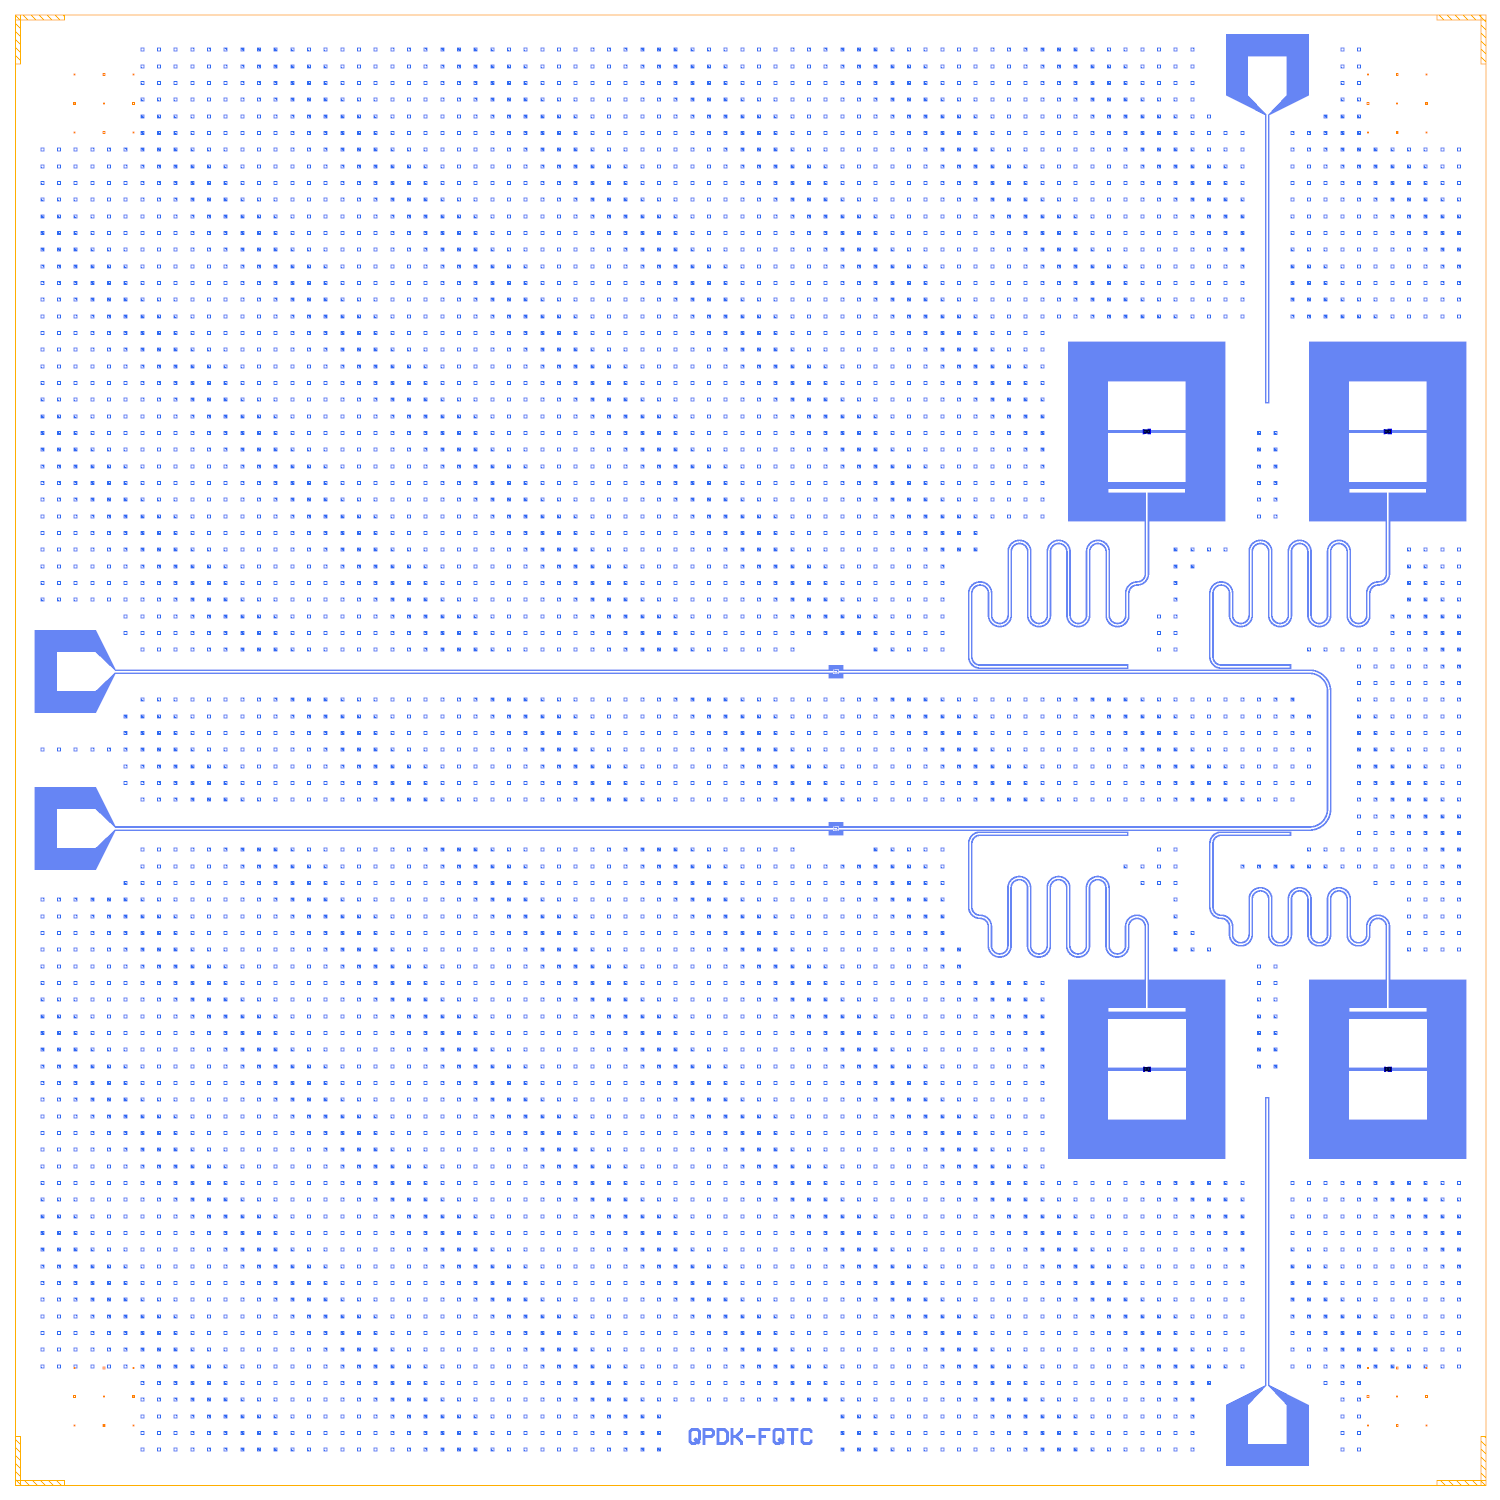

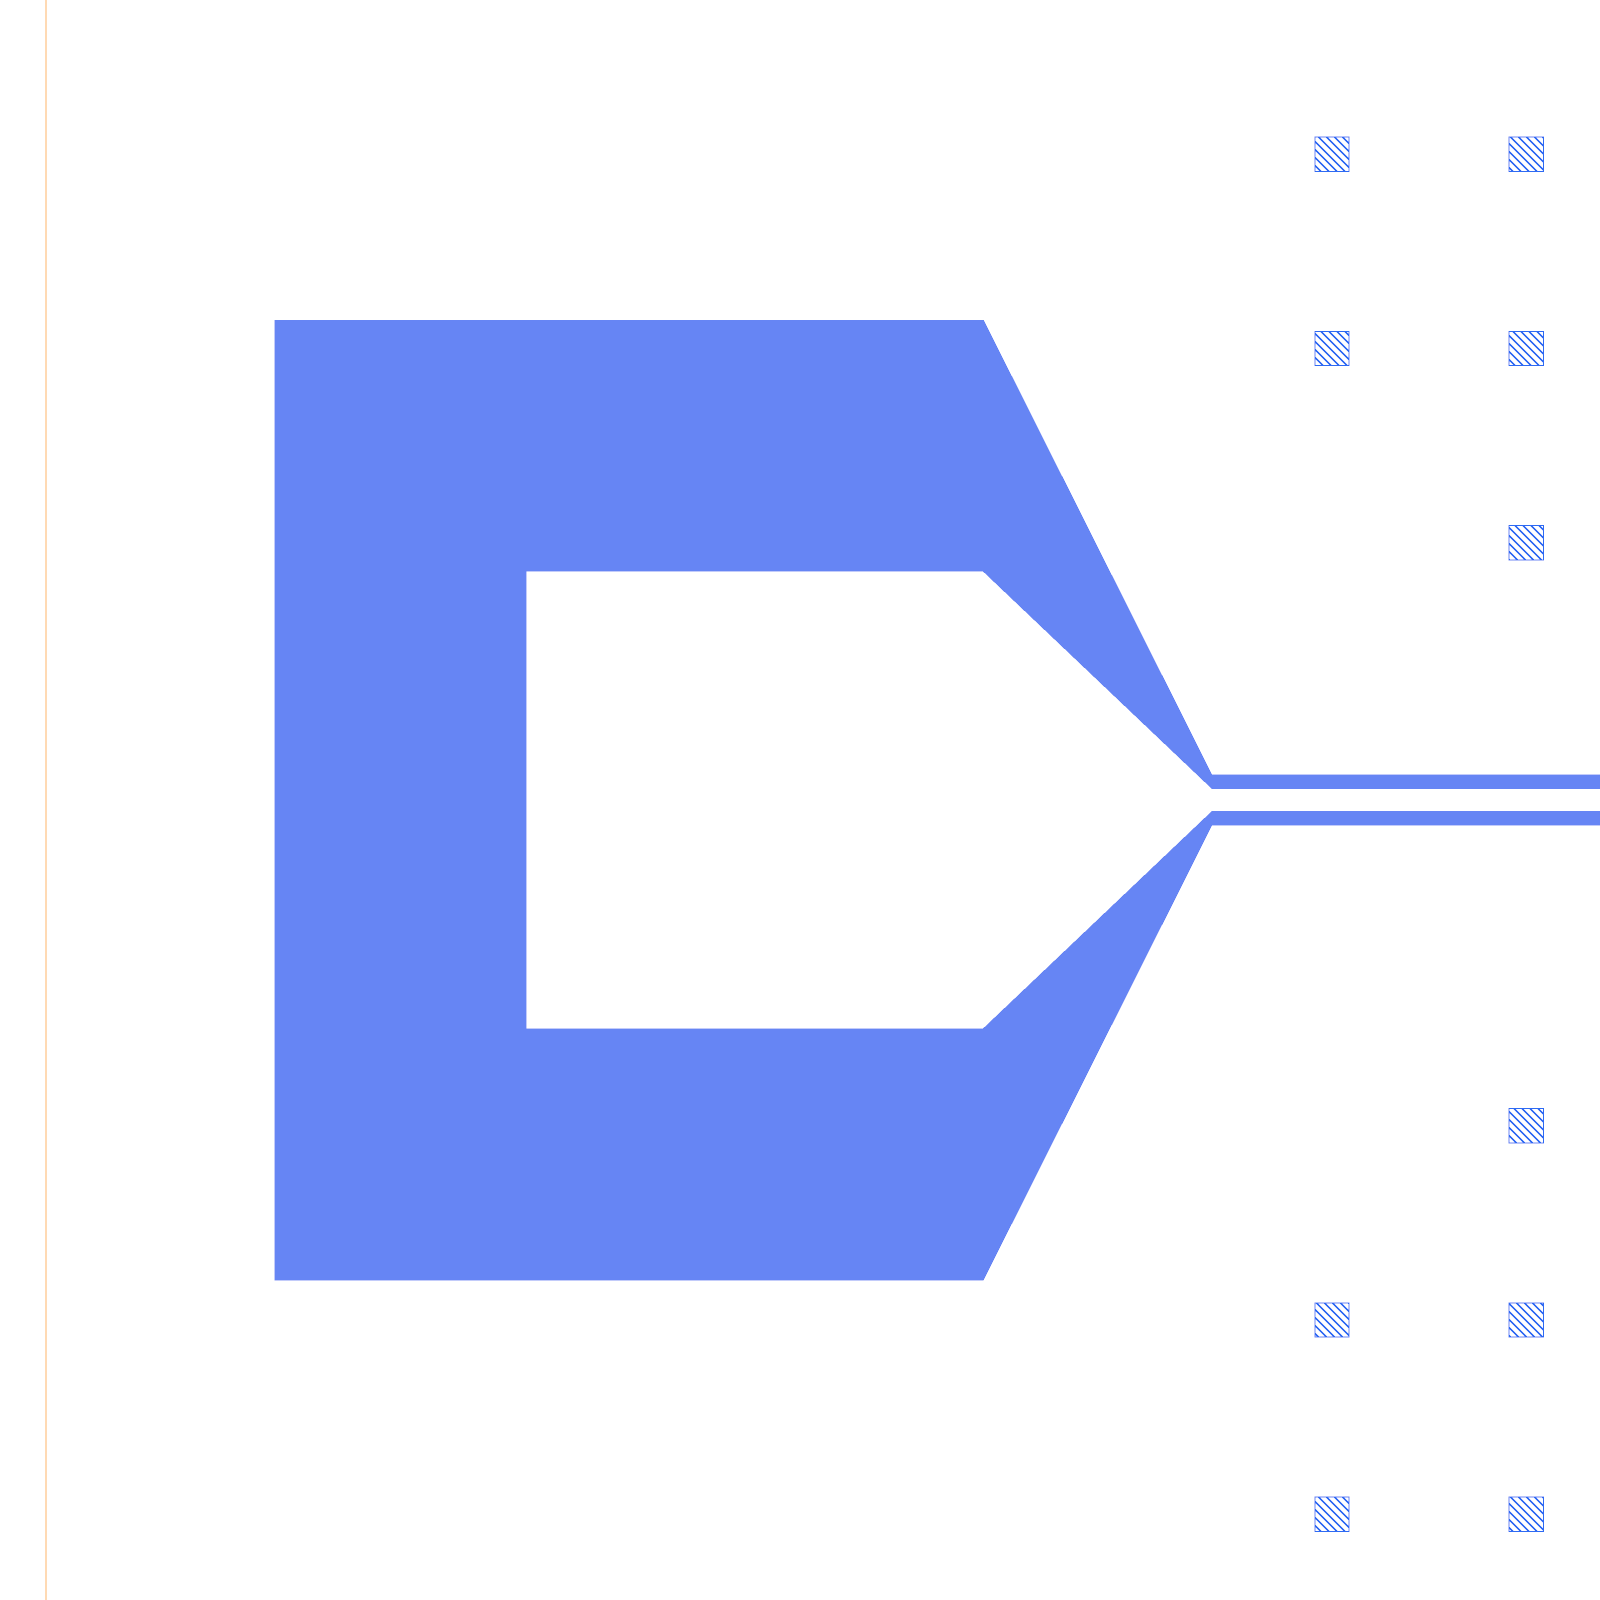

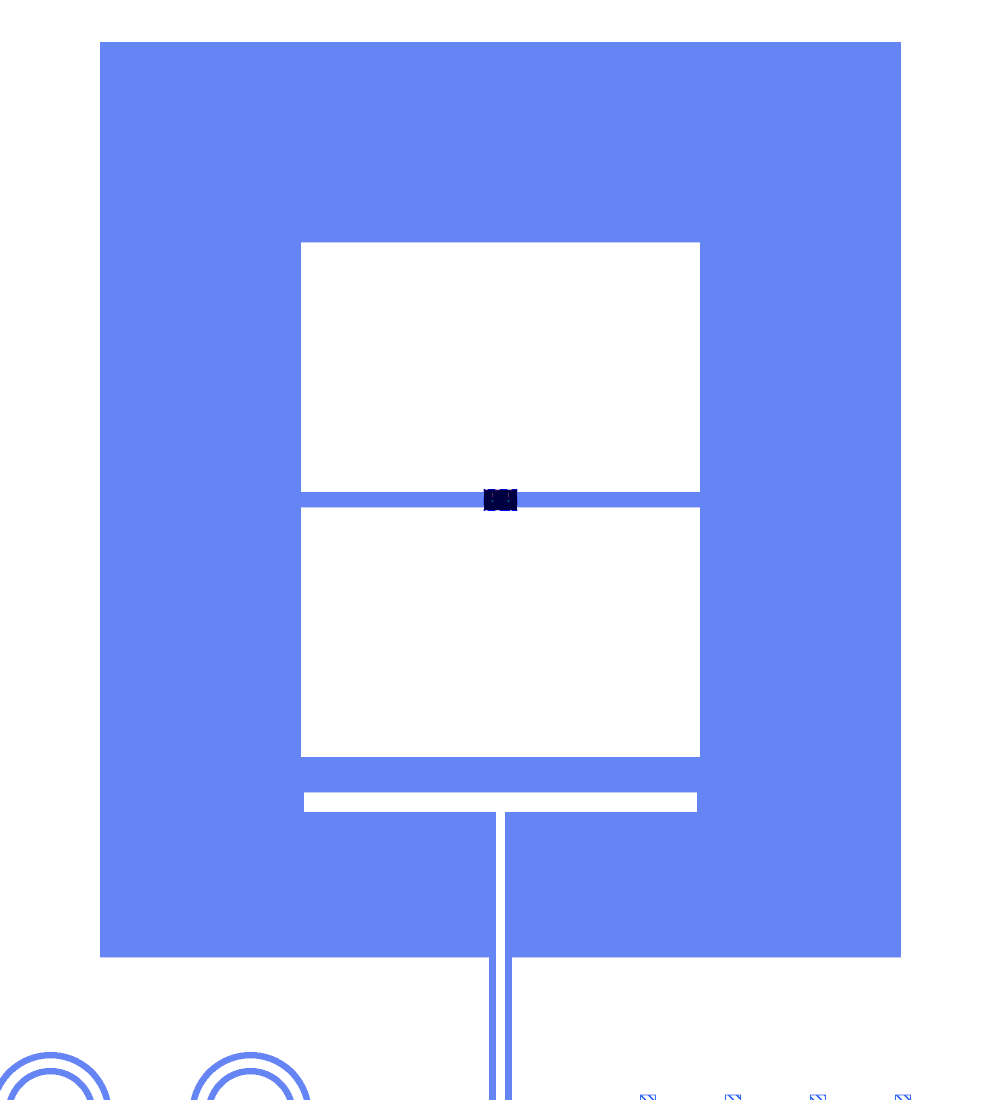

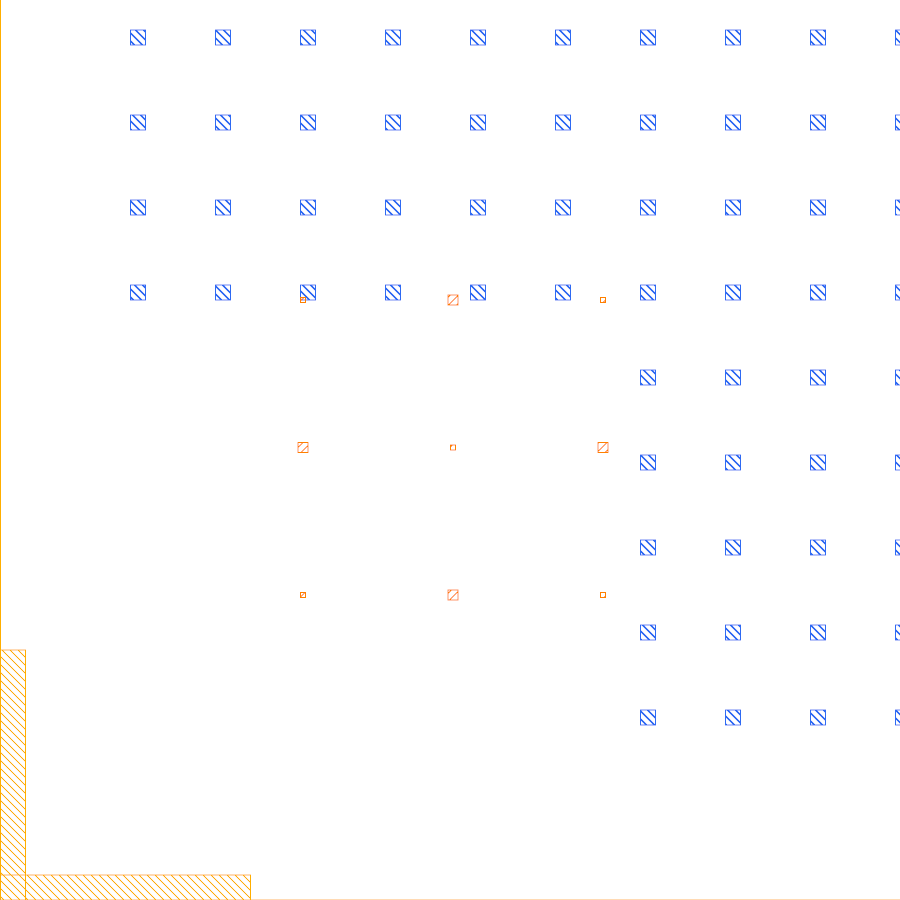

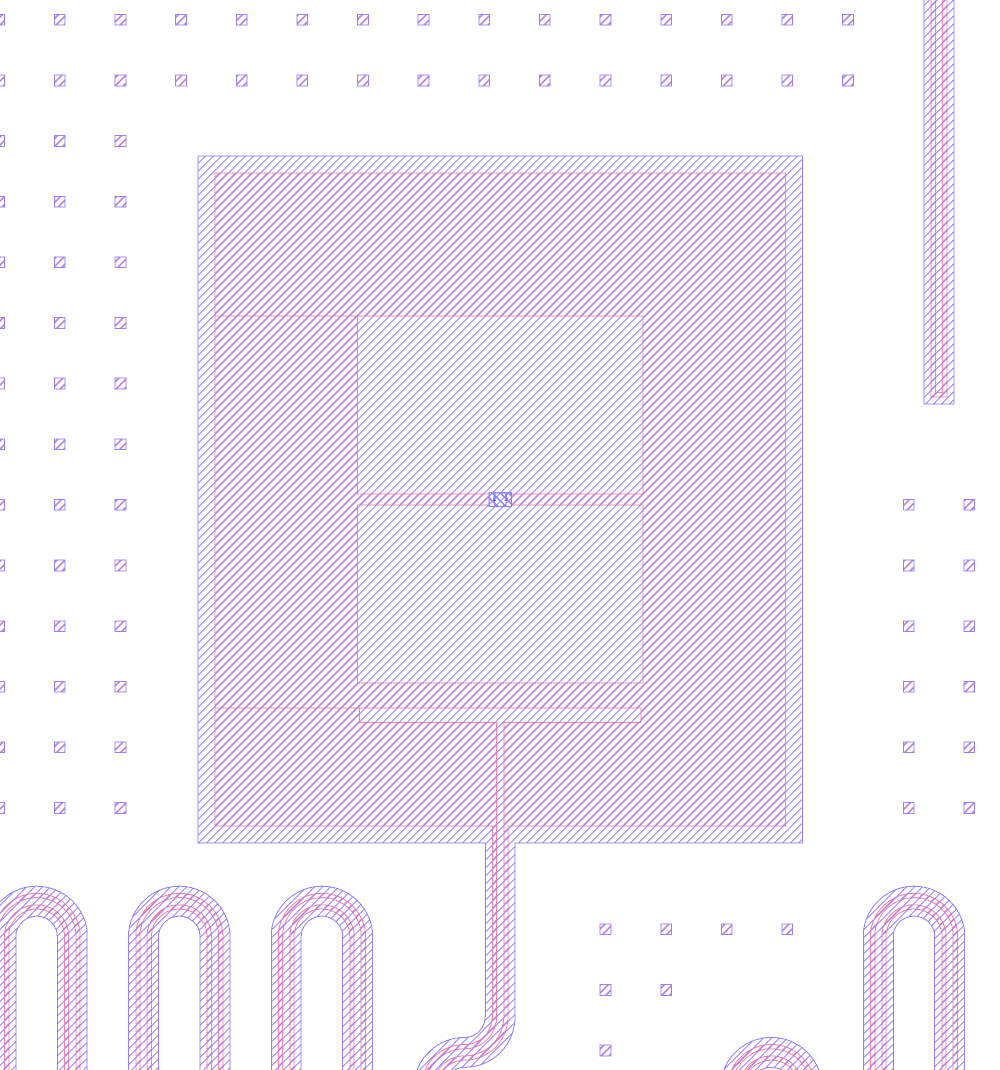

In [15]:
show_snapshot(d, OUT / "filled_qubit_test_chip.png", size=(1500, 1500))
x0, y0, _, _ = d.design.chip.box
_, py = port_xy(d, "PAD_IN.a")
show_snapshot(d, OUT / "filled_qubit_test_chip_edge.png", box=(x0 - 20, py - 300, x0 + 680, py + 300), width=420)
qx, qy = d.data["instances"]["Q1"]["place"]["at"]
show_snapshot(d, OUT / "filled_qubit_test_chip_q1.png", box=(qx - 500, qy - 600, qx + 500, qy + 500), size=(1000, 1100), width=420)
show_snapshot(d, OUT / "filled_qubit_test_chip_frame.png", box=(-1625, -650, -725, 250), size=(900, 900), width=300)
snap_file(Path("build") / "filled_qubit_test_chip_fab.oas", OUT / "filled_qubit_test_chip_fab_q1.png",
          box=(qx - 700, qy - 800, qx + 700, qy + 700), size=(1000, 1070), width=420);

**The original.** gdsfactory is not installed in this environment, so the source is not rebuilt here; QPDK's own
render of the filled chip is shown from the local clone when present.

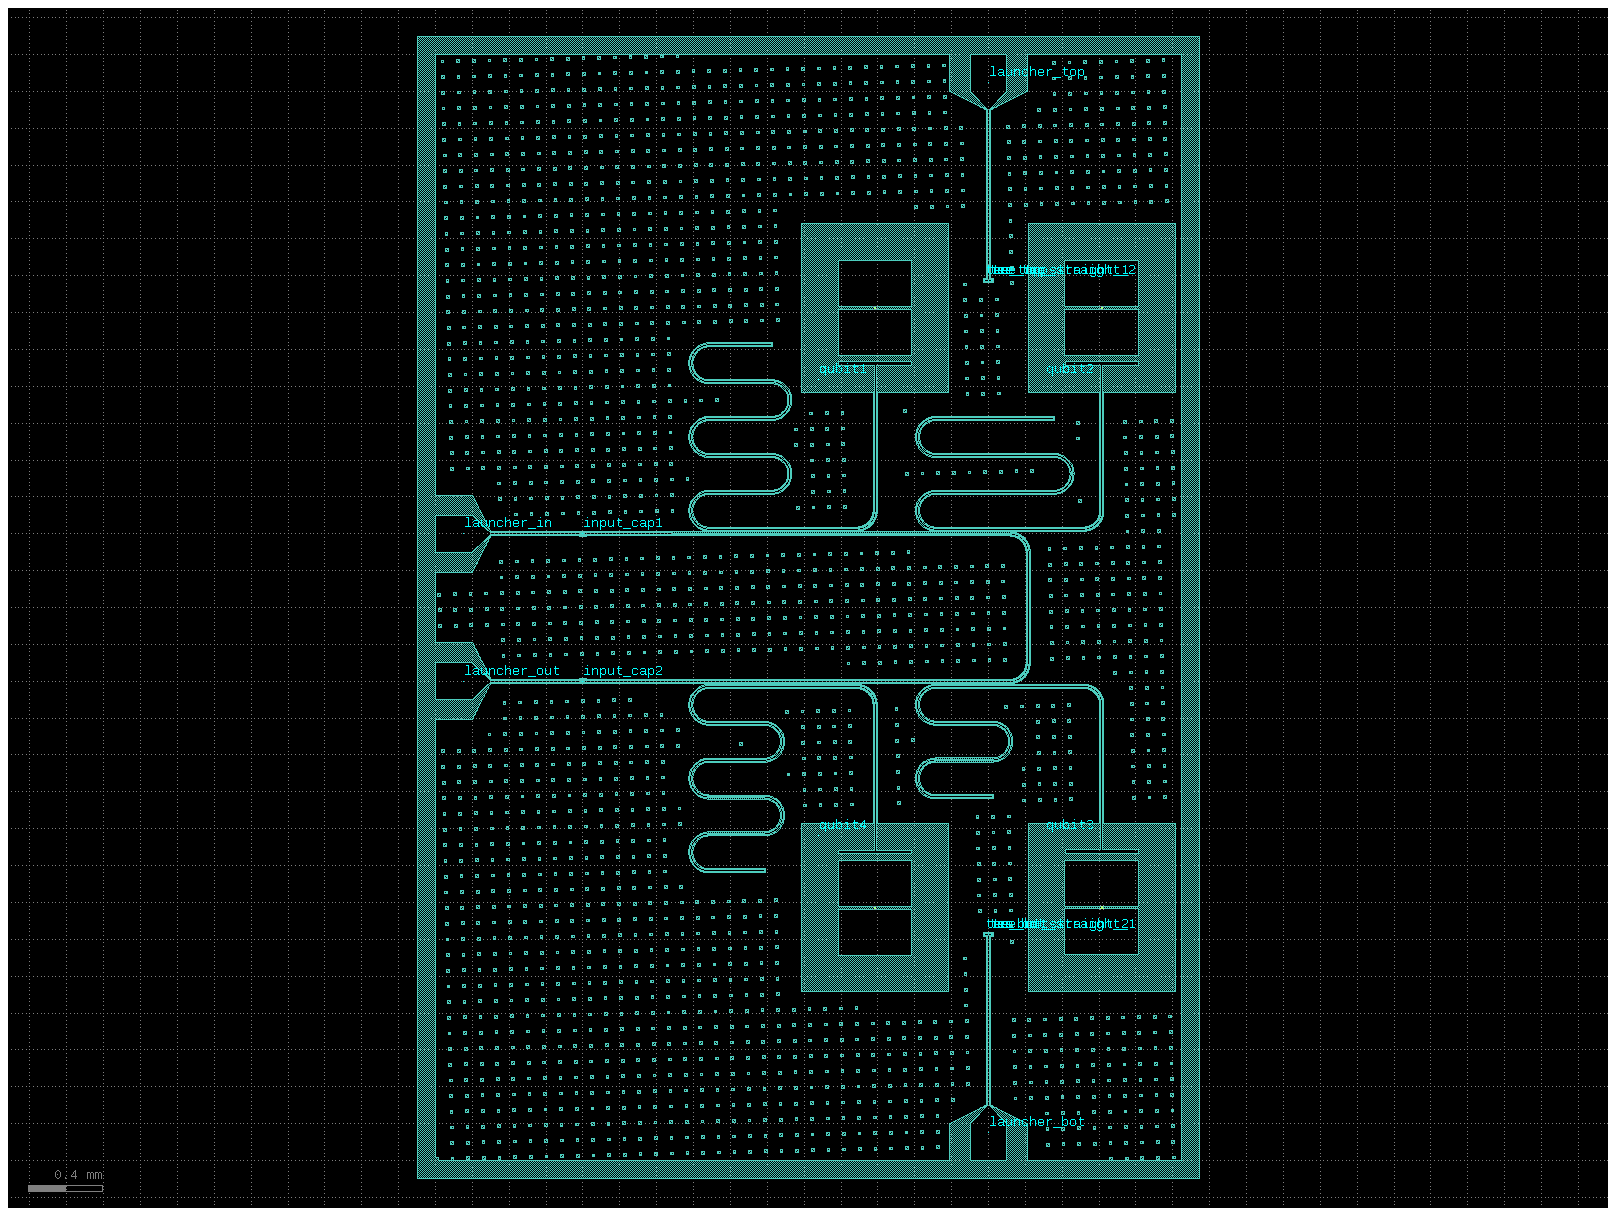

In [16]:
SRC_IMG = Path("build/external/quantum-rf-pdk/docs/_static/images") / "filled_qubit_test_chip.png"   # QPDK's own render (MIT), from the local clone if present
if SRC_IMG.exists():
    display(Image(filename=str(SRC_IMG), width=420))
else:
    print("QPDK image not in this checkout: "
          "https://github.com/gdsfactory/quantum-rf-pdk/blob/main/docs/_static/images/filled_qubit_test_chip.png")

## 15 · Summary

| | |
|---|---|
| **matches the source** | the whole qubit test chip (loaded unchanged); QPDK's vortex fill: 15 µm squares on an 85 µm pitch, 80 µm clear of the CPWs |
| **differs (PDK)** | everything the qubit test chip changes (7.5 mm die and frame, pads 100 µm from the edge, the whole layout centred, sapphire, trilayer SQUIDs); the frame instead of QPDK's etched chip edge; the fill covers the die inside the frame (QPDK: the layout's bounding box) |
| **not reproduced** | the 2 µm row stagger of the fill (a `CheeseRule` is a square grid); QPDK fills only the layout's bounding box, the rebuild the whole design area |
| **PDK design warnings** | none |
| **FEM** | 8 jobs exported to `build/jobs/filled_qubit_test_chip_*` (no fill in simulation), not solved here |